# Start

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)

## Utils

In PyTorch, calling model.eval() sets the model to evaluation (inference) mode.

This is a helper method that sets the training attribute of the model (and all its sub-modules/layers) to False (i.e., self.training = False).

It primarily changes the behavior of two types of layers:

1. Dropout (nn.Dropout): During training, dropout randomly zeroes some of the elements of the input tensor with probability $p$ to prevent overfitting. During evaluation (model.eval()), dropout is disabled, and the input is passed through unchanged (multiplied by a scaling factor if necessary).

2. Batch Normalization (nn.BatchNorm2d, etc.): During training, these layers track and use the mean and variance of the current mini-batch to normalize the features, while maintaining a running estimate of the global mean and variance. During evaluation (model.eval()), the layers stop updating these statistics and instead use the accumulated running mean and variance to normalize the inputs.

`Important Note on Gradient Calculation`
model.eval() does not disable gradient computation or free up memory used by gradients. To turn off gradient calculation during evaluation (which speeds up inference and reduces memory usage), you should wrap your evaluation code in a torch.no_grad() context manager:


In [8]:
import torch
import matplotlib.pyplot as plt



def plot_results(model, distances, times):
    """
    Plots the actual data points and the model's predicted line for a given dataset.

    Args:
        model: The trained machine learning model to use for predictions.
        distances: The input data points (features) for the model.
        times: The target data points (labels) for the plot.
    """
    # Set the model to evaluation mode
    model.eval()

    # Disable gradient calculation for efficient inference
    with torch.no_grad():
        # Make predictions using the trained model
        predicted_times = model(distances)

    # Create a new figure for the plot
    plt.figure(figsize=(8, 6))
    
    # Plot the actual data points
    plt.plot(distances.numpy(), times.numpy(), color='orange', marker='o', linestyle='None', label='Actual Delivery Times')
    
    # Plot the predicted line from the model
    plt.plot(distances.numpy(), predicted_times.numpy(), color='green', marker='None', label='Predicted Line')
    
    # Set the title of the plot
    plt.title('Actual vs. Predicted Delivery Times')
    # Set the x-axis label
    plt.xlabel('Distance (miles)')
    # Set the y-axis label
    plt.ylabel('Time (minutes)')
    # Display the legend
    plt.legend()
    # Add a grid to the plot
    plt.grid(True)
    # Show the plot
    plt.show()


In [27]:
def plot_nonlinear_comparison(model, new_distances, new_times):
    """
    Compares and plots the predictions of a model against new, non-linear data.

    Args:
        model: The trained model to be evaluated.
        new_distances: The new input data for generating predictions.
        new_times: The actual target values for comparison.
    """
    # Set the model to evaluation mode
    model.eval()
    
    # Disable gradient computation for inference
    with torch.no_grad():
        # Generate predictions using the model
        predictions = model(new_distances)

    # Create a new figure for the plot
    plt.figure(figsize=(8, 6))
    
    # Plot the actual data points
    plt.plot(new_distances.numpy(), new_times.numpy(), color='orange', marker='o', linestyle='None', label='Actual Data (Bikes & Cars)')
    
    # Plot the predictions from the model
    plt.plot(new_distances.numpy(), predictions.numpy(), color='green', marker='None', label='Linear Model Predictions')
    
    # Set the title of the plot
    plt.title('Linear Model vs. Non-Linear Reality')
    # Set the label for the x-axis
    plt.xlabel('Distance (miles)')
    # Set the label for the y-axis
    plt.ylabel('Time (minutes)')
    # Add a legend to the plot
    plt.legend()
    # Add a grid to the plot for better readability
    plt.grid(True)
    # Display the plot
    plt.show()

## Begin

In [2]:
distances = torch.tensor([[1.0], [2.0], [3.0], [4.0]], dtype=torch.float32)
times = torch.tensor([[6.96], [12.11], [16.77], [22.21]], dtype=torch.float32)

In [3]:
model = nn.Sequential(nn.Linear(1, 1))

In [4]:
loss_function = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

In [7]:
for epoch in range(500):
    optimizer.zero_grad()
    outputs = model(distances)
    loss = loss_function(outputs, times)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}: Loss = {loss.item()}")

Epoch 50: Loss = 0.03944866359233856
Epoch 100: Loss = 0.035811737179756165
Epoch 150: Loss = 0.0331188440322876
Epoch 200: Loss = 0.03112369030714035
Epoch 250: Loss = 0.029645616188645363
Epoch 300: Loss = 0.02855011820793152
Epoch 350: Loss = 0.0277385413646698
Epoch 400: Loss = 0.027137158438563347
Epoch 450: Loss = 0.026691725477576256
Epoch 500: Loss = 0.026361485943198204


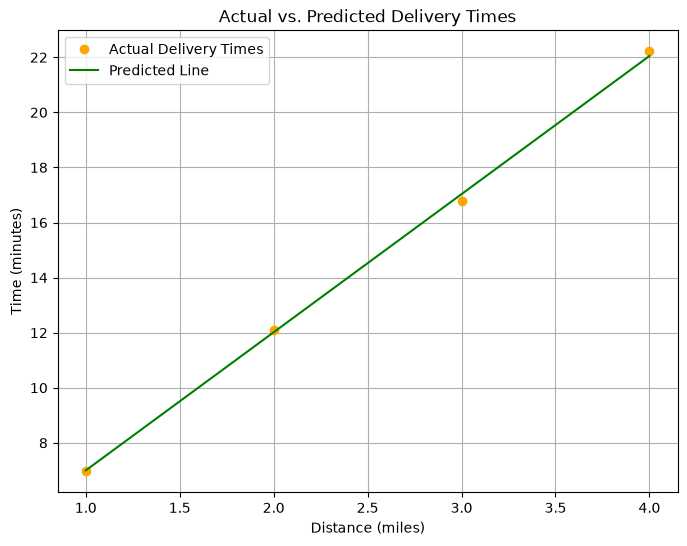

In [9]:
plot_results(model, distances, times)

In [14]:
model[0].bias

Parameter containing:
tensor([1.9850], requires_grad=True)

In [16]:
m0 = model[0]

In [19]:
for p in m0.parameters():
    print(p)

Parameter containing:
tensor([[5.0155]], requires_grad=True)
Parameter containing:
tensor([1.9850], requires_grad=True)


In [20]:
m0.eval()

Linear(in_features=1, out_features=1, bias=True)

In [21]:
with torch.no_grad():
    distance = torch.tensor([[10.0]], dtype=torch.float32)
    prediction = model(distance)

    print(prediction)

tensor([[52.1400]])


### weights and bias

In [22]:
layer = model[0]

weights = layer.weight.data.numpy()
bias = layer.bias.data.numpy()

print(f"weights = {weights}, bias = {bias}")

weights = [[5.015503]], bias = [1.9849645]


In [23]:
# Combined dataset: bikes for short distances, cars for longer ones
new_distances = torch.tensor([
    [1.0], [1.5], [2.0], [2.5], [3.0], [3.5], [4.0], [4.5], [5.0], [5.5],
    [6.0], [6.5], [7.0], [7.5], [8.0], [8.5], [9.0], [9.5], [10.0], [10.5],
    [11.0], [11.5], [12.0], [12.5], [13.0], [13.5], [14.0], [14.5], [15.0], [15.5],
    [16.0], [16.5], [17.0], [17.5], [18.0], [18.5], [19.0], [19.5], [20.0]
], dtype=torch.float32)

# Corresponding delivery times in minutes
new_times = torch.tensor([
    [6.96], [9.67], [12.11], [14.56], [16.77], [21.7], [26.52], [32.47], [37.15], [42.35],
    [46.1], [52.98], [57.76], [61.29], [66.15], [67.63], [69.45], [71.57], [72.8], [73.88],
    [76.34], [76.38], [78.34], [80.07], [81.86], [84.45], [83.98], [86.55], [88.33], [86.83],
    [89.24], [88.11], [88.16], [91.77], [92.27], [92.13], [90.73], [90.39], [92.98]
], dtype=torch.float32)

In [24]:
with torch.no_grad():
    predictions = model(new_distances)

In [25]:
new_loss = loss_function(predictions, new_times)
print(f"Loss on new, combined data: {new_loss.item():.2f}")

Loss on new, combined data: 179.26


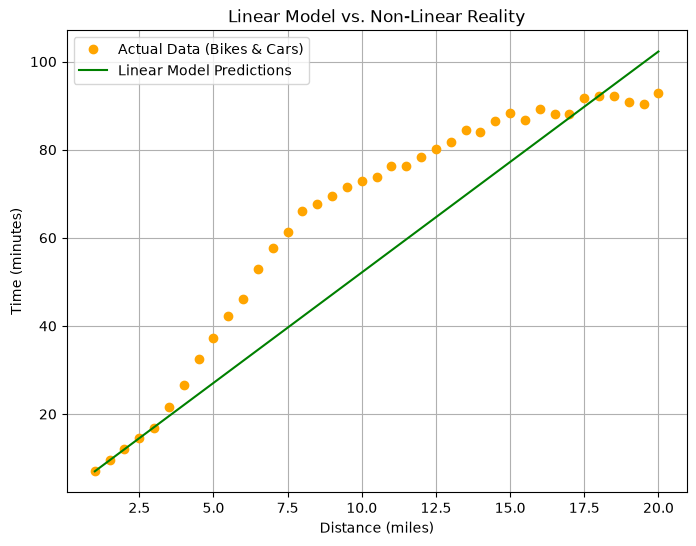

In [28]:
plot_nonlinear_comparison(model, new_distances, new_times)